# TD04 — Évaluer un modèle, courbes d'apprentissage et élan

## Objectif

Ce TD prolonge le TD03 (MLP et rétropropagation) et le chapitre « 5 - Évaluer un modèle ». On y **mesure** la qualité d'un modèle au lieu de la supposer : matrice de confusion et métriques adaptées aux classes déséquilibrées, puis courbes d'apprentissage sur un jeu d'entraînement et un jeu de test.

On étudie ensuite l'**élan** (momentum) : son effet sur la vitesse d'apprentissage et sur le surapprentissage, lu sur les courbes d'apprentissage. Le réglage des hyper-paramètres (protocole entraînement / validation / test) est abordé en bonus.

Les données sont générées par des fonctions fournies (blobs déséquilibrés, lunes, spirales) ; le MLP fourni est un perceptron multicouche à activations tanh (couches cachées) et sigmoïde (sortie).

## Préambule

Les cellules ci-dessous sont fournies : alias de types, générateurs de données, classe `MLP` (même structure qu'au TD03, activations figées) et fonctions de tracé.

Dans tout le TD, la graine d'initialisation des poids (`seed=0`) et le pas d'apprentissage (`LR = 0.5`) sont fixés : ce sont les valeurs par défaut de `MLP` et de `fit`. On ne les précise que lorsqu'on les change.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Alias de types pour les tableaux numpy
Vec = np.ndarray[tuple[int], np.dtype[np.float64]]        # vecteur 1D de flottants
Mat = np.ndarray[tuple[int, int], np.dtype[np.float64]]   # matrice 2D de flottants

### Générateurs de données

Chaque générateur renvoie `X` de forme $(n, 2)$ et les cibles `t` de forme $(n, 1)$, en flottants `0.` / `1.`. L'argument `seed` fixe le tirage. `split` mélange un jeu et le découpe en entraînement, test, et un reste mis de côté.

In [2]:
def make_blobs_imbalanced(n: int, noise: float = 0.6, pos_frac: float = 0.1, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux nuages gaussiens, classe 1 minoritaire.

    Classe 0 centrée en (0, 0), classe 1 centrée en (1, 1) ; chaque point est
    de classe 1 avec la probabilité `pos_frac`.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    lab = (rng.uniform(size=n) < pos_frac).astype(float)
    centers = np.where(lab[:, None] == 1, [1.0, 1.0], [0.0, 0.0])
    X = centers + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None]


def make_moons(n: int, noise: float = 0.3, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux demi-lunes entrelacées, bruit gaussien d'écart-type `noise`.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    a = rng.uniform(0.0, np.pi, size=n)
    lab = rng.integers(0, 2, size=n)
    x = np.where(lab == 0, np.cos(a), 1.0 - np.cos(a))
    y = np.where(lab == 0, np.sin(a), 0.5 - np.sin(a))
    X = np.c_[x, y] + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None].astype(float)


def make_spirals(n: int, noise: float = 0.08, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux spirales entrelacées (rayon r dans [0.2, 1], angle 3πr, +π pour la classe 1).

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    lab = rng.integers(0, 2, size=n)
    r = rng.uniform(0.2, 1.0, size=n)
    theta = 3 * np.pi * r + lab * np.pi
    X = np.c_[r * np.cos(theta), r * np.sin(theta)] + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None].astype(float)


def split(X: Mat, t: Mat, n_train: int, n_test: int, seed: int = 0) -> tuple[Mat, Mat, Mat, Mat, Mat, Mat]:
    """Mélange les exemples puis renvoie X_tr, t_tr, X_te, t_te, X_rest, t_rest.

    Les `n_train` premiers exemples pour l'entraînement, les `n_test`
    suivants pour le test, le reste est mis de côté.
    """
    perm = np.random.default_rng(seed).permutation(len(X))
    X, t = X[perm], t[perm]
    a, b = n_train, n_train + n_test
    return X[:a], t[:a], X[a:b], t[a:b], X[b:], t[b:]

### Le réseau

`MLP(sizes, seed=0)` : couches cachées en tanh, sortie sigmoïde, poids initialisés selon $\mathcal N(0, 0.5)$, biais nuls. Le coût est celui du cours, $E = \tfrac12\,\operatorname{mean}\sum_k (Y_k - T_k)^2$, et `error_rate` donne la proportion d'exemples mal classés au seuil choisi.

`fit(X, t, epochs, lr=LR)` effectue une étape de descente de gradient par époque (sur tout le jeu) et enregistre l'historique **après** chaque étape : l'entrée `i` de l'historique correspond à l'état du modèle après `i + 1` étapes. Le coût et le taux d'erreur sur le jeu d'entraînement sont enregistrés sous les clés `"train_loss"` et `"train_err"`. Si un jeu de test est fourni (`X_test`, `t_test`), le coût et le taux d'erreur sur ce jeu sont aussi enregistrés, sous les clés `"test_loss"` et `"test_err"` (listes vides sinon). Le test ne sert qu'à **mesurer** : il ne modifie jamais les poids.

In [3]:
LR = 0.5  # pas d'apprentissage, commun à tout le TD


class MLP:
    def __init__(self, sizes: list[int], seed: int = 0):
        rng = np.random.default_rng(seed)
        self.sizes = list(sizes)
        self.Ws: list[Mat] = []
        self.bs: list[Vec] = []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            self.Ws.append(rng.normal(0.0, 0.5, size=(n_out, n_in)))
            self.bs.append(np.zeros(n_out))

    def _forward(self, X: Mat) -> tuple[list[Mat], list[Mat]]:
        """Passe avant : renvoie (As, Zs), activations (avec Y0 = X en tête) et pré-activations."""
        A = X
        As = [A]
        Zs = []
        n = len(self.Ws)
        for l, (W, b) in enumerate(zip(self.Ws, self.bs)):
            Z = A @ W.T + b
            Zs.append(Z)
            A = 1.0 / (1.0 + np.exp(-Z)) if l == n - 1 else np.tanh(Z)
            As.append(A)
        return As, Zs

    def backward(self, X: Mat, t: Mat) -> list[tuple[Mat, Vec]]:
        """Passe arrière : liste de (dW_l, db_l), une paire par couche."""
        As, Zs = self._forward(X)
        N = X.shape[0]
        Y = As[-1]
        delta = (Y - t) * Y * (1.0 - Y)
        grads: list[tuple[Mat, Vec]] = []
        for l in reversed(range(len(self.Ws))):
            dW = delta.T @ As[l] / N
            db = delta.mean(axis=0)
            grads.append((dW, db))
            if l > 0:
                delta = (delta @ self.Ws[l]) * (1.0 - np.tanh(Zs[l - 1]) ** 2)
        grads.reverse()
        return grads

    def step(self, X: Mat, t: Mat, lr: float) -> None:
        """Une étape de descente de gradient sur le jeu (X, t)."""
        for l, (dW, db) in enumerate(self.backward(X, t)):
            self.Ws[l] = self.Ws[l] - lr * dW
            self.bs[l] = self.bs[l] - lr * db

    def predict(self, X: Mat) -> Mat:
        """Probabilités de la classe 1, de forme (N, 1)."""
        return self._forward(X)[0][-1]

    def loss(self, X: Mat, t: Mat) -> float:
        """Coût : E = (1/2) · mean(Σ_k (Y_k - T_k)²)."""
        return 0.5 * float(np.mean(np.sum((self.predict(X) - t) ** 2, axis=1)))

    def error_rate(self, X: Mat, t: Mat, threshold: float = 0.5) -> float:
        """Proportion d'exemples mal classés (classe 1 prédite si la probabilité est supérieure ou égale à `threshold`)."""
        return float(np.mean((self.predict(X) >= threshold) != (t > 0.5)))

    def fit(self, X: Mat, t: Mat, epochs: int, lr: float = LR,
            X_test: Mat | None = None, t_test: Mat | None = None) -> dict[str, list[float]]:
        """Entraîne le réseau (une étape par époque) et renvoie l'historique.

        Clés : `"train_loss"`, `"test_loss"` (coûts) et `"train_err"`, `"test_err"`
        (taux d'erreur). L'entrée i est mesurée après i + 1 étapes ; les listes
        `"test_loss"` et `"test_err"` restent vides sans jeu de test.
        """
        history: dict[str, list[float]] = {"train_loss": [], "test_loss": [], "train_err": [], "test_err": []}
        has_test = X_test is not None and t_test is not None
        for _ in range(epochs):
            self.step(X, t, lr)
            history["train_loss"].append(self.loss(X, t))
            history["train_err"].append(self.error_rate(X, t))
            if has_test:
                history["test_loss"].append(self.loss(X_test, t_test))
                history["test_err"].append(self.error_rate(X_test, t_test))
        return history

### Tracés

`plot_curves` superpose les courbes d'apprentissage de plusieurs entraînements (une couleur par entrée ; train en pointillés, test en trait plein). Avec `metric="err"`, on trace les taux d'erreur au lieu du coût. `plot_data` affiche un nuage de points coloré par classe (classe 0 en rouge, classe 1 en bleu), `plot_decision` ajoute la frontière de décision d'un modèle (probabilité 0.5).

In [4]:
def plot_curves(histories: dict[str, dict[str, list[float]]], metric: str = "loss",
                logx: bool = True, ax=None):
    """Courbes d'apprentissage de plusieurs historiques sur un même graphique.

    `metric="loss"` trace le coût, `metric="err"` les taux d'erreur.
    """
    if ax is None:
        fig, ax = plt.subplots()
    k_tr, k_va = ("train_loss", "test_loss") if metric == "loss" else ("train_err", "test_err")
    if len(histories) == 1:
        h = next(iter(histories.values()))
        x = np.arange(1, len(h[k_tr]) + 1)
        ax.plot(x, h[k_tr], color="C0", ls="--", lw=1, label="train")
        if h[k_va]:
            ax.plot(x, h[k_va], color="C0", label="test")
    else:
        has_test = False
        for i, (name, h) in enumerate(histories.items()):
            c = f"C{i}"
            x = np.arange(1, len(h[k_tr]) + 1)
            ax.plot(x, h[k_tr], color=c, ls="--", lw=1)
            if h[k_va]:
                ax.plot(x, h[k_va], color=c, label=name)
                has_test = True
            else:
                ax.plot([], [], color=c, ls="--", label=name)
        ax.plot([], [], color="gray", ls="--", lw=1, label="train")
        if has_test:
            ax.plot([], [], color="gray", label="test")
    ax.set_xlabel("époque")
    ax.set_ylabel("coût" if metric == "loss" else "taux d'erreur")
    if logx:
        ax.set_xscale("log")
    if metric == "loss":
        ax.set_yscale("log")
    ax.legend()
    ax.grid(True)
    return ax


def plot_data(X: Mat, t: Mat, ax=None):
    """Nuage de points coloré par classe (classe 0 en rouge, classe 1 en bleu), avec légende."""
    if ax is None:
        fig, ax = plt.subplots()
    for k, color in ((0, "tab:red"), (1, "tab:blue")):
        mask = t.ravel() == k
        ax.scatter(X[mask, 0], X[mask, 1], color=color, label=f"classe {k}",
                   edgecolors="w", linewidths=0.5, s=25, zorder=3)
    ax.legend(loc="upper left")
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True)
    return ax


def plot_decision(model: MLP, X: Mat, t: Mat, ax=None):
    """Probabilité prédite (fond), frontière à 0.5 (trait noir) et points (X, t)."""
    if ax is None:
        fig, ax = plt.subplots()
    m = 0.3
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - m, X[:, 0].max() + m, 200),
                         np.linspace(X[:, 1].min() - m, X[:, 1].max() + m, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.linspace(0, 1, 21), cmap="RdBu", alpha=0.6)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=2)
    plot_data(X, t, ax=ax)
    return ax

## 1. Évaluer un classifieur : la matrice de confusion

Pour un classifieur binaire, la classe **positive** (1) est la classe d'intérêt (la fraude, la maladie, l'intrusion…) ; la sortie sigmoïde est seuillée à 0.5. Dans ce TD, $y$ désigne la prédiction 0/1 obtenue en seuillant la sortie sigmoïde $Y$ (la probabilité de la classe 1). Comparer les prédictions $y$ aux cibles $t$ donne quatre comptes, rangés dans la **matrice de confusion** :

| | prédit positif ($y = 1$) | prédit négatif ($y = 0$) |
|---|---|---|
| **réel positif** ($t = 1$) | TP (vrais positifs) | FN (faux négatifs) |
| **réel négatif** ($t = 0$) | FP (faux positifs) | TN (vrais négatifs) |

À partir de ces comptes, avec $N = \mathrm{TP} + \mathrm{FP} + \mathrm{TN} + \mathrm{FN}$ :

- **accuracy** (taux de bonne classification) : $\dfrac{\mathrm{TP} + \mathrm{TN}}{N}$ ;
- **précision** : $\dfrac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FP}}$, parmi les exemples prédits positifs, la part qui l'est vraiment ;
- **rappel** : $\dfrac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}}$, parmi les vrais positifs, la part détectée.

Par convention, la précision vaut 0 lorsqu'aucun exemple n'est prédit positif ($\mathrm{TP} + \mathrm{FP} = 0$), et le rappel vaut 0 lorsqu'il n'y a aucun positif réel.

### 1.1 Les données

On utilise deux nuages gaussiens dont la classe 1 est minoritaire (chaque point est positif avec une probabilité de 0.1) : un petit jeu d'entraînement (100 points) et un grand jeu de test (1000 points), tirés avec des graines différentes. La cellule suivante les génère et les affiche.

train : 100 points, 8 positifs
test  : 1000 points, 80 positifs (8.0%)


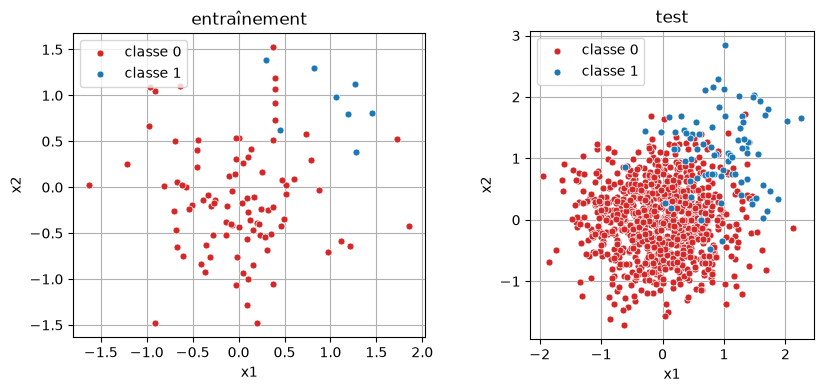

In [5]:
Xb_tr, tb_tr = make_blobs_imbalanced(100, seed=1)
Xb_te, tb_te = make_blobs_imbalanced(1000, seed=2)
print(f"train : {len(tb_tr)} points, {int(tb_tr.sum())} positifs")
print(f"test  : {len(tb_te)} points, {int(tb_te.sum())} positifs ({tb_te.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_data(Xb_tr, tb_tr, ax=axes[0]); axes[0].set_title("entraînement")
plot_data(Xb_te, tb_te, ax=axes[1]); axes[1].set_title("test")
plt.show()

### 1.2 Matrice de confusion

La fonction `classify`, fournie, transforme les sorties `Y` du réseau (probabilités) en prédictions 0./1. de forme `(N,)` : la classe 1 est prédite si la probabilité est supérieure **ou égale** à `threshold` (0.5 par défaut).

In [6]:
def classify(Y: Mat, threshold: float = 0.5) -> Vec:
    """Prédictions 0/1 à partir des probabilités de la classe 1.

    `Y` est la sortie du réseau, de forme (N, 1) (une colonne, une ligne par
    exemple). Renvoie un vecteur de forme (N,) : 1. si la probabilité est
    supérieure ou égale à `threshold`, 0. sinon. `Y.ravel()` aplatit
    (N, 1) en (N,).
    """
    return (Y.ravel() >= threshold).astype(float)


<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 1</legend>

Complétez `confusion`, qui renvoie le tuple `(TP, FP, TN, FN)` ; `t` et `y` sont des étiquettes 0/1 de forme `(N,)` ou `(N, 1)`.

</fieldset>

In [7]:
def confusion(t: Vec | Mat, y: Vec | Mat) -> tuple[int, int, int, int]:
    """Comptes (TP, FP, TN, FN) de la matrice de confusion.

    `t` (cibles) et `y` (prédictions) contiennent des 0. / 1. et peuvent
    être de forme (N, 1), comme les cibles renvoyées par les générateurs, ou
    (N,), comme la sortie de `classify`. Les aplatir d'abord en (N,) avec
    `.ravel()` : comparer directement un (N, 1) à un (N,) diffuserait en une
    matrice (N, N) et fausserait les comptes.
    """
    # BEGIN
    # raise NotImplementedError
    ## Indice : aplatir t et y, puis compter avec des masques booléens (t == 1) & (y == 1), etc.
    t = t.ravel()
    y = y.ravel()
    tp = int(np.sum((t == 1) & (y == 1)))
    fp = int(np.sum((t == 0) & (y == 1)))
    tn = int(np.sum((t == 0) & (y == 0)))
    fn = int(np.sum((t == 1) & (y == 0)))
    return tp, fp, tn, fn
    # END

In [8]:
def check_confusion():
    t = np.array([1, 1, 1, 0, 0, 0, 0, 0.])
    y = np.array([1, 0, 0, 1, 0, 0, 0, 0.])
    assert confusion(t, y) == (1, 1, 4, 2), "confusion incorrecte"
    assert confusion(t.reshape(-1, 1), y) == (1, 1, 4, 2), "confusion incorrecte avec t de forme (N, 1)"
    print("confusion check — OK")

check_confusion()

confusion check — OK


### 1.3 Accuracy, précision, rappel

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 2</legend>

Complétez `accuracy`, `precision` et `recall` en vous appuyant sur `confusion`. Si le dénominateur est nul, `precision` et `recall` renvoient `0.0` (sans division par zéro ni avertissement).

</fieldset>

In [9]:
def accuracy(t: Vec | Mat, y: Vec | Mat) -> float:
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return (tp + tn) / (tp + fp + tn + fn)
    # END


def precision(t: Vec | Mat, y: Vec | Mat) -> float:
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return tp / (tp + fp) if tp + fp > 0 else 0.0
    # END


def recall(t: Vec | Mat, y: Vec | Mat) -> float:
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return tp / (tp + fn) if tp + fn > 0 else 0.0
    # END

In [10]:
import warnings

def check_metrics():
    t = np.array([1, 1, 1, 0, 0, 0, 0, 0.])
    y = np.array([1, 0, 0, 1, 0, 0, 0, 0.])
    y0 = np.zeros(8)
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        assert accuracy(t, y) == 5 / 8, "accuracy incorrecte"
        assert precision(t, y) == 0.5, "precision incorrecte"
        assert recall(t, y) == 1 / 3, "recall incorrect"
        assert precision(t, y0) == 0.0, "precision doit valoir 0 si aucun positif prédit"
        assert recall(t, y0) == 0.0, "recall incorrect pour le classifieur toujours négatif"
        assert accuracy(t, y0) == 5 / 8, "accuracy incorrecte pour le classifieur toujours négatif"
    print("metrics check — OK")

check_metrics()

metrics check — OK


### 1.4 Le piège de l'accuracy

Pour comparer plusieurs classifieurs, on regroupe d'abord la matrice de confusion et les trois métriques dans un seul dictionnaire.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 3</legend>

Complétez `evaluate` en vous appuyant sur `confusion` et sur les fonctions de l'exercice 2. Le format du dictionnaire renvoyé est donné dans la docstring. La fonction `show`, fournie, l'affiche sur une ligne.

</fieldset>

In [11]:
def evaluate(t: Vec | Mat, y: Vec | Mat) -> dict[str, float]:
    """Matrice de confusion et métriques des prédictions `y` par rapport aux cibles `t`.

    `t` et `y` sont de forme (N,) ou (N, 1), comme pour `confusion`. Renvoie un
    dictionnaire à sept clés :

    - "TP", "FP", "TN", "FN" : les quatre comptes de `confusion` (entiers) ;
    - "accuracy", "precision", "recall" : les trois métriques (flottants).
    """
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "accuracy": accuracy(t, y),
            "precision": precision(t, y),
            "recall": recall(t, y)}
    # END

In [12]:
def check_evaluate():
    t = np.array([1, 1, 1, 0, 0, 0, 0, 0.])
    y = np.array([1, 0, 0, 1, 0, 0, 0, 0.])
    res = evaluate(t, y)
    assert (res["TP"], res["FP"], res["TN"], res["FN"]) == (1, 1, 4, 2), "comptes incorrects"
    assert res["accuracy"] == 5 / 8 and res["precision"] == 0.5 and res["recall"] == 1 / 3, "métriques incorrectes"
    print("evaluate check — OK")

check_evaluate()

evaluate check — OK


In [13]:
def show(name: str, res: dict[str, float]) -> None:
    counts = "  ".join(f"{k}={int(res[k])}" for k in ("TP", "FP", "TN", "FN"))
    print(f"{name:18s} {counts}  | accuracy={res['accuracy']:.3f}  "
          f"précision={res['precision']:.3f}  rappel={res['recall']:.3f}")

On peut maintenant mesurer le piège annoncé dans le cours : sur des classes déséquilibrées, un classifieur qui ne détecte rien peut avoir une très bonne accuracy.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 4</legend>

On compare, **sur le jeu de test**, deux classifieurs :

1. **le classifieur « toujours négatif »** : il n'apprend rien et répond « classe 0 » pour chaque point, quel qu'il soit. C'est la référence la plus bête possible ; un vrai modèle doit faire mieux que lui.
2. **un MLP entraîné** : un réseau `MLP([2, 16, 1])`, nommé `model`, entraîné **uniquement sur le jeu d'entraînement** (100 points) avec `fit` et `epochs=4000`. Une fois entraîné, on lui fait prédire les probabilités des points **de test**, que `classify` transforme en prédictions 0./1.

Pour chacun, construisez le vecteur de ses prédictions sur le jeu de test : une valeur 0. ou 1. par point de test, de forme `(N,)` avec `N = 1000`. Nommez-les `y_zero` et `y_mlp`. Après la vérification, la cellule suivante affiche, avec `evaluate` et `show`, la matrice de confusion et les métriques de chacun par rapport aux cibles du test `tb_te`.

Comparez les deux lignes : lequel a la meilleure accuracy, et de combien ? Lequel détecte des positifs ?

</fieldset>

In [14]:
# BEGIN
## Rappel: Xb_tr:  données de train,  tb_tr: target de train
# y_zero = ... 
# model = ...
# ...
# y_mlp = ...
y_zero = np.zeros(len(tb_te))
model = MLP([2, 16, 1])
model.fit(Xb_tr, tb_tr, epochs=4000)
y_mlp = classify(model.predict(Xb_te))
# END

In [15]:
def check_predictions():
    assert y_zero.shape == (len(tb_te),) and not y_zero.any(), "y_zero doit être le vecteur nul de forme (N,)"
    assert y_mlp.shape == (len(tb_te),), "y_mlp doit avoir la forme (N,)"
    assert set(np.unique(y_mlp)) <= {0.0, 1.0}, "y_mlp doit contenir des prédictions 0./1."
    print("prédictions check — OK")

check_predictions()

prédictions check — OK


In [16]:
show("toujours négatif", evaluate(tb_te, y_zero))
show("MLP [2, 16, 1]", evaluate(tb_te, y_mlp))

toujours négatif   TP=0  FP=0  TN=920  FN=80  | accuracy=0.920  précision=0.000  rappel=0.000
MLP [2, 16, 1]     TP=46  FP=18  TN=902  FN=34  | accuracy=0.948  précision=0.719  rappel=0.575


#### Lecture des résultats

Le classifieur « toujours négatif » ne détecte aucun des 80 positifs du test (rappel nul, précision nulle par convention), et pourtant son accuracy vaut 0.920 : les négatifs représentent 92 % des exemples. Le MLP atteint 0.948, soit seulement 2,8 points de plus, alors qu'il détecte 46 positifs sur 80 (rappel 0.575, précision 0.719).

Sur des classes déséquilibrées, l'accuracy ne distingue donc pas un classifieur inutile d'un classifieur utile ; ce sont la précision et le rappel, lus avec la matrice de confusion, qui renseignent sur la classe minoritaire.

### 1.5 Le seuil : précision contre rappel

La sortie du MLP est une probabilité ; le seuil de décision est un réglage, pas une fatalité. Baisser le seuil prédit plus d'exemples positifs, l'élever en prédit moins.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 5</legend>

Complétez `sweep_threshold`, qui renvoie la précision et le rappel obtenus sur `(X, t)` pour chaque seuil de `thresholds`. Après la vérification, on trace les deux courbes en fonction du seuil, pour le MLP entraîné à l'exercice 4.

</fieldset>

In [17]:
def sweep_threshold(model: MLP, X: Mat, t: Mat, thresholds: Vec) -> tuple[Vec, Vec]:
    """Précision et rappel du modèle sur `(X, t)`, pour chaque seuil de décision.

    - `X` est le vecteur d'entrée (de forme (N, 2))
    - `t` (cibles 0./1.) de forme (N, 1)
    - `thresholds` est un vecteur de K seuils entre 0 et 1. 

    Renvoie deux vecteurs de forme (K,) : `precs[k]` et `recs[k]` sont la
    précision et le rappel obtenus avec le seuil `thresholds[k]`.
    """
    # BEGIN
    # raise NotImplementedError
    ## Indice : utiliser la fonction classify
    Y = model.predict(X)
    precs = np.array([precision(t, classify(Y, s)) for s in thresholds])
    recs = np.array([recall(t, classify(Y, s)) for s in thresholds])
    return precs, recs
    # END

In [18]:
def check_sweep():
    class Fixe:
        def predict(self, X):
            return np.array([[0.9], [0.6], [0.4], [0.2], [0.1]])
    t = np.array([[1.], [0.], [1.], [0.], [0.]])
    precs, recs = sweep_threshold(Fixe(), None, t, np.array([0.3, 0.5, 0.95]))
    # seuil 0.3 : y = [1, 1, 1, 0, 0] -> TP=2, FP=1, FN=0 ; seuil 0.5 : y = [1, 1, 0, 0, 0] -> TP=1, FP=1, FN=1
    # seuil 0.95 : y = 0 partout -> précision 0 (convention), rappel 0
    assert np.array_equal(precs, np.array([2 / 3, 0.5, 0.0])), "précisions incorrectes"
    assert np.array_equal(recs, np.array([1.0, 0.5, 0.0])), "rappels incorrects"
    print("sweep check — OK")

check_sweep()

sweep check — OK


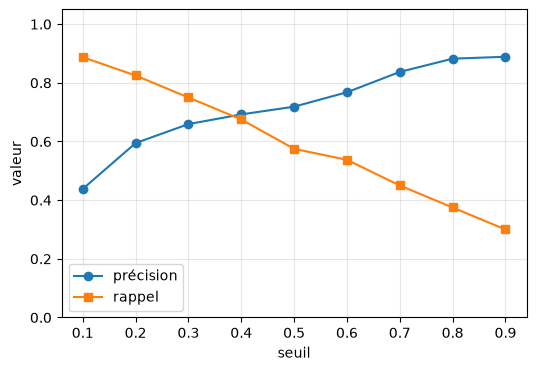

In [19]:
thresholds = np.linspace(0.1, 0.9, 9)
precs, recs = sweep_threshold(model, Xb_te, tb_te, thresholds)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thresholds, precs, "o-", label="précision")
ax.plot(thresholds, recs, "s-", label="rappel")
ax.set_xlabel("seuil"); ax.set_ylabel("valeur"); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 6</legend>

Pour un détecteur de fraude bancaire (la fraude est la classe positive), faut-il privilégier la précision ou le rappel ? Quel seuil serait-on tenté de choisir, et quel prix paie-t-on ?

</fieldset>

*Votre réponse :*

# TOCLEAR
**Le rappel.** Une fraude non détectée (faux négatif) coûte bien plus cher qu'une alerte injustifiée (faux positif), qui se règle par une vérification : on veut détecter le plus de fraudes possible. On abaisse donc le seuil : à 0.1, le rappel monte à 0.888 contre 0.575 à 0.5. Le prix est une précision plus faible (0.438 contre 0.719) : plus de la moitié des alertes sont de fausses alertes, qu'il faut traiter. Le choix du seuil dépend du coût relatif d'un faux négatif et d'un faux positif.

## 2. Courbes d'apprentissage

Un réseau est jugé sur des données qu'il n'a **pas** vues pendant l'entraînement (le *hold-out* du chapitre 1). On découpe donc les données en deux jeux :

- **entraînement** (train) : sert à calculer les gradients et à modifier les poids ;
- **test** : sert seulement à **mesurer** l'erreur sur des données nouvelles ; le réseau ne s'entraîne jamais dessus.

Une **courbe d'apprentissage** trace l'erreur en fonction des époques, pour l'entraînement **et** pour le test, sur le même graphe.

### 2.1 Entraîner et tracer les courbes

On travaille sur le jeu des deux lunes (bruit gaussien 0.3). Le jeu d'entraînement est volontairement **petit** (60 points) pour que le réseau, bien plus grand qu'il n'en faut (deux couches cachées de 32 neurones), puisse apprendre le bruit par cœur. Le test (500 points) est plus grand, donc plus fiable. Les 500 points restants sont mis de côté pour le bonus : on ne s'en sert pas d'ici là.

La cellule suivante entraîne le réseau **sans élan** par descente de gradient sur le lot complet, en mesurant à chaque époque le coût et le taux d'erreur sur le jeu d'entraînement et sur le jeu de test. L'historique est rangé dans `hist_plain`. On affiche ensuite les courbes (axe des époques en échelle logarithmique), puis la frontière de décision finale.

train : 60 points, test : 500 points (+ 500 mis de côté pour le bonus)


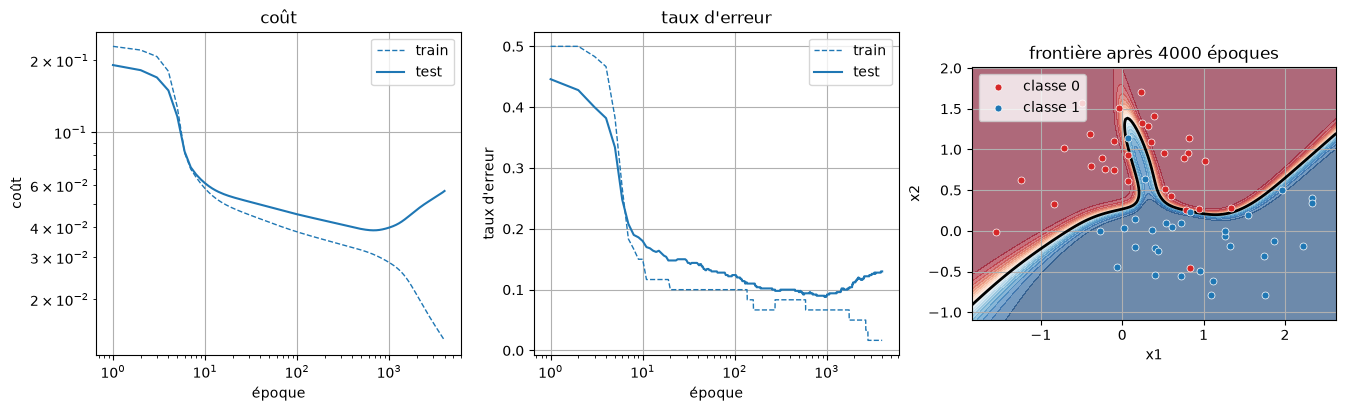

In [20]:
SIZES = [2, 32, 32, 1]
EPOCHS = 4000

X, t = make_moons(1060, noise=0.3, seed=1)
X_tr, t_tr, X_te, t_te, X_new, t_new = split(X, t, n_train=60, n_test=500)
print(f"train : {len(t_tr)} points, test : {len(t_te)} points (+ {len(t_new)} mis de côté pour le bonus)")

model_plain = MLP(SIZES)
hist_plain = model_plain.fit(X_tr, t_tr, epochs=EPOCHS, X_test=X_te, t_test=t_te)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_curves({"μ=0": hist_plain}, metric="loss", ax=axes[0])
axes[0].set_title("coût")
plot_curves({"μ=0": hist_plain}, metric="err", ax=axes[1])
axes[1].set_title("taux d'erreur")
plot_decision(model_plain, X_tr, t_tr, ax=axes[2])
axes[2].set_title(f"frontière après {EPOCHS} époques")
plt.show()

### 2.2 Lire les courbes

Une courbe d'apprentissage prend l'un des profils suivants :

- **sous-apprentissage** : coûts d'entraînement et de test tous deux élevés, le réseau n'a pas encore appris ;
- **bon régime** : les deux coûts baissent ensemble, avec un écart faible entre eux ;
- **surapprentissage** : le coût d'entraînement continue de baisser mais celui de test **remonte**, l'écart se creuse ;
- **instabilité** : des oscillations ou une divergence (pas d'apprentissage trop grand, ou, on le verra, élan trop grand).

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 7</legend>

On souhaite obtenir les valeurs précises de l'époque à laquelle arrêter l'entraînement, ainsi que la valeur de test associée. 

Complétez la cellule ci-dessous.
</fieldset>

In [21]:
# BEGIN
## Rappel : hist_plain["test_loss"] est la liste des coûts de test, un par époque.
## Indice : np.argmin donne l'indice du minimum.
# best_idx = ...
# best_test = ...
best_idx = int(np.argmin(hist_plain["test_loss"]))
best_test = hist_plain["test_loss"][best_idx]
# END

In [22]:
def check_best_idx():
    assert isinstance(best_idx, (int, np.integer)), "best_idx doit être un entier (indice dans hist_plain[\"test\"])"
    assert isinstance(best_test, (float, np.floating)), "best_test doit être un nombre"
    assert 0 <= best_idx < EPOCHS, "best_idx doit être un indice d'époque valide"
    assert best_test == min(hist_plain["test_loss"]), "best_test n'est pas le minimum du coût de test"
    assert hist_plain["test_loss"][best_idx] == best_test, "best_idx ne pointe pas sur le minimum"
    print("lecture du minimum — OK")

check_best_idx()

lecture du minimum — OK


In [23]:
print(f"minimum du coût de test : {best_test:.4f} à l'indice {best_idx} (après {best_idx + 1} étapes)")
print(f"coût d'entraînement à ce moment : {hist_plain['train_loss'][best_idx]:.4f}")
print(f"taux d'erreur de test à ce moment : {hist_plain['test_err'][best_idx]:.3f}")
best_idx_err = int(np.argmin(hist_plain["test_err"]))
print(f"minimum du taux d'erreur de test : {hist_plain['test_err'][best_idx_err]:.3f} à l'indice {best_idx_err}")
print(f"fin d'entraînement : coût train {hist_plain['train_loss'][-1]:.4f}, coût test {hist_plain['test_loss'][-1]:.4f}, "
      f"erreur train {hist_plain['train_err'][-1]:.3f}, erreur test {hist_plain['test_err'][-1]:.3f}")

minimum du coût de test : 0.0389 à l'indice 679 (après 680 étapes)
coût d'entraînement à ce moment : 0.0308
taux d'erreur de test à ce moment : 0.094
minimum du taux d'erreur de test : 0.088 à l'indice 944
fin d'entraînement : coût train 0.0135, coût test 0.0568, erreur train 0.017, erreur test 0.130


<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 8</legend>

À l'aide des courbes et des valeurs affichées :
1. Où se situe le sous-apprentissage (quelles époques, quelles valeurs de coût) ?
2. Où commence le surapprentissage, et que fait le coût d'entraînement pendant ce temps ?
3. Le coût de test et le taux d'erreur de test racontent-ils exactement la même chose ? Comparez l'époque de leur minimum.

</fieldset>

*Votre réponse :*

# TOCLEAR
1. **Sous-apprentissage** : seulement les toutes premières époques, environ les 10 premières. Après une étape, le coût de test vaut 0.191 et le taux d'erreur de test 0.446, soit presque le hasard ; après 5 étapes 0.117 et 0.334 ; les deux coûts sont élevés et chutent très vite. Vers l'époque 10 les courbes quittent ce plateau (coût de test 0.061, taux d'erreur 0.18). Ensuite, de l'époque 10 au minimum, c'est le **bon régime** : les coûts d'entraînement et de test baissent ensemble, lentement et proches l'un de l'autre (à l'époque 100 : 0.038 en entraînement, 0.045 en test, taux d'erreur de test 0.124).
2. **Surapprentissage** : il commence au minimum du coût de test, 0.0389 à l'indice 679. Ensuite le coût de test remonte (à 0.0568 à la fin) alors que le coût d'entraînement continue de baisser, de 0.0308 à 0.0135 : le réseau apprend le bruit des 60 points d'entraînement, l'écart se creuse. Le taux d'erreur d'entraînement tombe à 0.017 (un seul point mal classé) alors que celui de test remonte à 0.130.
3. **Presque la même histoire, pas tout à fait** : le taux d'erreur de test reste proche de 0.088 sur un long plateau, avec son minimum à l'indice 944 (contre 679 pour le coût) ; il vaut 0.094 à l'indice du minimum du coût. Le coût mesure aussi la confiance des sorties (une sortie trop sûre d'elle et fausse coûte cher), le taux d'erreur seulement le côté du seuil 0.5 : le coût détecte donc le surapprentissage plus tôt.

## 3. L'élan à travers les courbes

### 3.1 La règle d'élan

À chaque étape, la descente de gradient simple déplace les poids de $-\eta\,\partial E/\partial W$. L'**élan** (momentum) ajoute une *vitesse* $v$ qui garde la mémoire des étapes précédentes :

$$v \leftarrow \mu\, v + \eta\,\frac{\partial E}{\partial W}, \qquad W \leftarrow W - v$$

(et de même pour les biais). L'image est celle d'une bille qui roule dans le paysage du coût : elle prend de la vitesse tant que la pente garde le même sens, et un coefficient $\mu$ proche de 1 lui fait garder longtemps son élan. Avec $\mu = 0$, on retrouve exactement la descente de gradient simple.

On compare ici, **dans des conditions identiques** (mêmes données, même initialisation, même $\eta$, même nombre d'époques), l'entraînement sans élan ($\mu = 0$, déjà fait dans `hist_plain`) et avec $\mu = 0.9$ et $\mu = 0.99$. Seul $\mu$ change.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 9</legend>

Complétez la méthode `step` de `MLPMomentum` : pour chaque couche, mettre à jour les vitesses `vWs[l]` et `vbs[l]` d'après les gradients renvoyés par `self.backward`, puis retirer la vitesse aux poids et aux biais. Le constructeur est fourni : il crée les vitesses (nulles, de mêmes formes que `Ws` et `bs`).

</fieldset>

In [24]:
class MLPMomentum(MLP):
    def __init__(self, sizes: list[int], seed: int = 0, momentum: float = 0.9):
        super().__init__(sizes, seed)
        self.momentum = momentum
        
        # vitesses accumulée (par couche), pour les poids liés aux entrées, et les poids liés aux biais.
        # On les initialise à 0
        self.vWs: list[Mat] = [np.zeros_like(W) for W in self.Ws]
        self.vbs: list[Vec] = [np.zeros_like(b) for b in self.bs]

    def step(self, X: Mat, t: Mat, lr: float) -> None:
        """
        Une étape de descente de gradient avec élan sur le jeu (X, t), avec momentum
        """
        # BEGIN
        # raise NotImplementedError
        ## Indice : Partir de l'implémentation sans momentum; rajouter la mise à jour de la vitesse pour chaque couche, 
        for l, (dW, db) in enumerate(self.backward(X, t)):
            self.vWs[l] = self.momentum * self.vWs[l] + lr * dW
            self.vbs[l] = self.momentum * self.vbs[l] + lr * db
            self.Ws[l] = self.Ws[l] - self.vWs[l]
            self.bs[l] = self.bs[l] - self.vbs[l]
        # END

In [25]:
def check_momentum():
    Xc = np.random.default_rng(0).normal(size=(5, 2))
    tc = (np.random.default_rng(1).uniform(size=(5, 1)) > 0.5).astype(float)

    # élan nul : même trajectoire que le MLP sans élan
    plain = MLP([2, 3, 1], seed=1)
    plain.fit(Xc, tc, epochs=3)
    zero = MLPMomentum([2, 3, 1], seed=1, momentum=0.0)
    zero.fit(Xc, tc, epochs=3)
    for l in range(len(plain.Ws)):
        assert np.allclose(zero.Ws[l], plain.Ws[l], atol=1e-12), f"avec momentum=0, Ws[{l}] diffère du MLP sans élan"
        assert np.allclose(zero.bs[l], plain.bs[l], atol=1e-12), f"avec momentum=0, bs[{l}] diffère du MLP sans élan"

    # élan 0.9, deux étapes : poids de référence
    ref_W = [np.array([[0.14673871803484698, 0.39851181588559315],
                       [0.19515453685032108, -0.6368897938974577],
                       [0.46981739983849297, 0.23128706456123407]]),
             np.array([[-0.22303683110313538, 0.267899150610648, 0.24655544403224489]])]
    ref_b = [np.array([-0.00955612603057793, 0.01376131709714779, 0.00525673780723384]),
             np.array([0.03565953506558011])]
    mom = MLPMomentum([2, 3, 1], seed=1, momentum=0.9)
    mom.fit(Xc, tc, epochs=2)
    sans = MLP([2, 3, 1], seed=1)
    sans.fit(Xc, tc, epochs=2)
    for l in range(len(ref_W)):
        assert np.allclose(mom.Ws[l], ref_W[l], atol=1e-8), f"Ws[{l}] incorrect après 2 étapes avec élan 0.9"
        assert np.allclose(mom.bs[l], ref_b[l], atol=1e-8), f"bs[{l}] incorrect après 2 étapes avec élan 0.9"
    assert not np.allclose(mom.Ws[0], sans.Ws[0], atol=1e-8), "avec élan 0.9, les poids doivent différer de ceux sans élan"

    # formes des vitesses
    for l in range(len(mom.Ws)):
        assert mom.vWs[l].shape == mom.Ws[l].shape, f"vWs[{l}] n'a pas la forme de Ws[{l}]"
        assert mom.vbs[l].shape == mom.bs[l].shape, f"vbs[{l}] n'a pas la forme de bs[{l}]"
    print("MLPMomentum check — OK")

check_momentum()

MLPMomentum check — OK


### 3.2 Trois élans, mêmes conditions

Nous allons maintenant comparer les courbes d'apprentissage pour plusieurs valeurs d'élans:
- élan nul (i.e. pas d'élan), pour lequel on a déjà entraîné un modèle.
- 0.9 et 0.99, pour lesquels nous allons entraîner des modèles.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 10</legend>

Complétez la cellule ci-dessous : 
pour chaque élan du dictionnaire `MUS`, entraînez un `MLPMomentum(SIZES, momentum=mu)`, avec les **mêmes** conditions que `hist_plain` (`epochs=EPOCHS`, jeux `X_tr`/`X_te`), et rangez chaque historique dans `hists` sous la clé correspondante. Le cas $\mu = 0$ est déjà dans `hists`. Après la vérification, la cellule suivante affiche les courbes de coût, puis un tableau récapitulatif.

</fieldset>

In [26]:
MUS = {"μ=0.9": 0.9, "μ=0.99": 0.99}
hists = {"μ=0": hist_plain}
# BEGIN
## Rappel : X_tr, t_tr : entraînement ; X_te, t_te : test ; mêmes SIZES et EPOCHS qu'au §2.
## Pour chaque (name, mu) : construire un MLPMomentum, l'entraîner avec fit, ranger l'historique renvoyé dans hists[name].
# for name, mu in MUS.items():
#     model_mu = ...
#     hists[name] = ...
for name, mu in MUS.items():
    model_mu = MLPMomentum(SIZES, momentum=mu)
    hists[name] = model_mu.fit(X_tr, t_tr, epochs=EPOCHS, X_test=X_te, t_test=t_te)
# END

In [27]:
def check_hists():
    assert list(hists) == ["μ=0", "μ=0.9", "μ=0.99"], f"clés attendues : μ=0, μ=0.9, μ=0.99 (obtenu : {list(hists)})"
    for name, h in hists.items():
        assert len(h["test_loss"]) == EPOCHS and len(h["train_loss"]) == EPOCHS, f"historique {name} de mauvaise longueur"
    # mêmes conditions que hist_plain : les premières époques de l'entraînement μ=0.9 se reproduisent exactement
    court = MLPMomentum(SIZES, momentum=0.9).fit(X_tr, t_tr, epochs=5, X_test=X_te, t_test=t_te)
    assert court["test_loss"] == hists["μ=0.9"]["test_loss"][:5], "μ=0.9 : conditions différentes de hist_plain (graine, lr, données ?)"
    print("hists check — OK")

check_hists()

hists check — OK


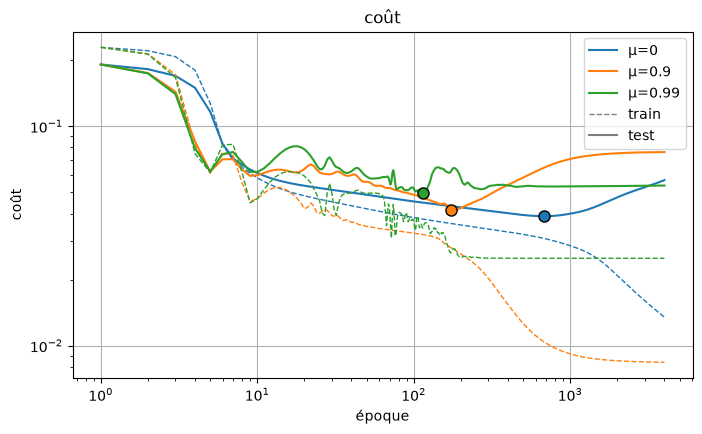

         indice du min min test  train au min  test final  train final  étapes train <= 0.03
μ=0                679   0.0389        0.0308      0.0568       0.0135                   789
μ=0.9              172   0.0415        0.0279      0.0762       0.0084                   151
μ=0.99             113   0.0497        0.0343      0.0536       0.0250                   161


In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_curves(hists, metric="loss", ax=ax)
ax.set_title("coût")
for i, h in enumerate(hists.values()):
    b = int(np.argmin(h["test_loss"]))
    ax.plot(b + 1, h["test_loss"][b], "o", color=f"C{i}", ms=8, mec="k", zorder=5)
plt.show()

print(f"{'':8s} {'indice du min':>13s} {'min test':>8s} {'train au min':>13s} {'test final':>11s} {'train final':>12s} {'étapes train <= 0.03':>21s}")
for name, h in hists.items():
    b = int(np.argmin(h["test_loss"]))
    seuil = int(np.argmax(np.array(h["train_loss"]) <= 0.03)) + 1 if min(h["train_loss"]) <= 0.03 else None
    print(f"{name:8s} {b:13d} {h['test_loss'][b]:8.4f} {h['train_loss'][b]:13.4f} {h['test_loss'][-1]:11.4f} {h['train_loss'][-1]:12.4f} {str(seuil):>21s}")

Le tableau compare les coûts. Pour juger les modèles eux-mêmes, on les arrête là où on les choisirait, au minimum de leur coût de test, et on mesure leurs performances de classification avec les outils du §1.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 11</legend>

Pour chaque élan de `MOMENTUMS` (les trois réglages de `hists`) :

1. calculez `n_steps`, le nombre d'étapes qui mène au minimum de son coût de test ;
2. entraînez un **nouveau** `MLPMomentum(SIZES, momentum=mu)` pendant `n_steps` étapes sur `X_tr`, `t_tr`, et rangez-le dans `best_models[name]` ;
3. rangez dans `res_best[name]` le résultat de `evaluate` sur le jeu de test : prédictions de `classify` (seuil 0.5) sur `X_te`, comparées aux cibles `t_te`.

Après la vérification, la cellule suivante affiche une ligne par élan avec `show`.

</fieldset>

In [29]:
MOMENTUMS = {"μ=0": 0.0, **MUS}
best_models = {}
res_best = {}
# BEGIN
## Rappel : hists[name]["test_loss"] est la liste des coûts de test, un par époque (indice i = après i + 1 étapes).
# for name, mu in MOMENTUMS.items():
#     n_steps = ...
#     best_models[name] = ...
#     ...
#     res_best[name] = ...
for name, mu in MOMENTUMS.items():
    n_steps = int(np.argmin(hists[name]["test_loss"])) + 1
    best_models[name] = MLPMomentum(SIZES, momentum=mu)
    best_models[name].fit(X_tr, t_tr, epochs=n_steps)
    res_best[name] = evaluate(t_te, classify(best_models[name].predict(X_te)))
# END

In [30]:
def check_res_best():
    assert list(res_best) == list(hists) and list(best_models) == list(hists), f"clés attendues : {list(hists)}"
    for name, m in best_models.items():
        assert m.momentum == MOMENTUMS[name], f"{name} : mauvais élan"
        assert m.loss(X_te, t_te) == min(hists[name]["test_loss"]), f"{name} : le modèle n'est pas arrêté au minimum du coût de test (nombre d'étapes ?)"
        assert res_best[name] == evaluate(t_te, classify(m.predict(X_te))), f"{name} : métriques incorrectes"
    print("res_best check — OK")

check_res_best()

res_best check — OK


In [31]:
for name, res in res_best.items():
    show(name, res)

μ=0                TP=235  FP=30  TN=218  FN=17  | accuracy=0.906  précision=0.887  rappel=0.933
μ=0.9              TP=236  FP=35  TN=213  FN=16  | accuracy=0.898  précision=0.871  rappel=0.937
μ=0.99             TP=226  FP=25  TN=223  FN=26  | accuracy=0.898  précision=0.900  rappel=0.897


<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 12</legend>

À l'aide des courbes, du tableau et des métriques de l'exercice 11 :
1. Combien de fois plus tôt l'élan $\mu = 0.9$ atteint-il le minimum du coût de test, par rapport à $\mu = 0$ ? Ce minimum est-il plus bas ?
2. À partir de quelle époque le surapprentissage commence-t-il pour chaque élan, et que devient le coût de test à la fin de l'entraînement ?
3. Que se passe-t-il pour $\mu = 0.99$ ?
4. L'élan améliore-t-il le modèle ? Que change-t-il, exactement ?
5. Les trois modèles ont-ils la même accuracy ? Font-ils pour autant les mêmes erreurs ?

</fieldset>

*Votre réponse :*

# TOCLEAR
1. **Environ 4 fois plus tôt.** Sans élan, le minimum du coût de test est à l'indice 679 (après 680 étapes) ; avec $\mu = 0.9$, à l'indice 172 (après 173 étapes), soit un facteur $680 / 173 \approx 3.9$. Le coût d'entraînement va dans le même sens : il passe sous 0.03 après 151 étapes avec $\mu = 0.9$ contre 789 sans élan (environ 5 fois plus tôt). En revanche le minimum n'est **pas plus bas** : 0.0415 avec $\mu = 0.9$ contre 0.0389 sans élan (légèrement plus haut, avec un seul tirage de graine on ne lit pas plus qu'« à peu près le même »).
2. Le surapprentissage commence au minimum du coût de test, puis le coût de test remonte tandis que celui d'entraînement continue de baisser : après l'indice 679 sans élan, après l'indice 172 avec $\mu = 0.9$. À la fin (4000 époques), le coût de test vaut 0.0568 pour $\mu = 0$ et 0.0762 pour $\mu = 0.9$ (le coût d'entraînement est tombé à 0.0084 contre 0.0135) : avec élan, on a parcouru plus vite un chemin comparable, donc on est plus loin dans le surapprentissage au même nombre d'époques.
3. Avec $\mu = 0.99$, la bille garde trop d'élan : la courbe de test oscille dans les premières dizaines d'époques (0.0697 à l'époque 30, plus haut qu'avec $\mu = 0.9$ où l'on a 0.0606), son minimum est le moins bon des trois (0.0497, indice 113), puis l'entraînement se bloque sur un plateau (coût d'entraînement 0.0250, soit 3 points d'entraînement sur 60 mal classés). Un élan trop grand rend la descente instable et peut empêcher de descendre aussi bas. Ce réglage ne surapprend pas, au sens strict, avant la fin : son coût de test final (0.0536) reste proche de son minimum (0.0497), alors que ceux de $\mu = 0$ et $\mu = 0.9$ ont nettement remonté (0.0568 et 0.0762, pour des minima de 0.0389 et 0.0415) ; mais c'est parce qu'il est bloqué sur un plateau d'entraînement, pas parce qu'il généralise mieux.
4. **Non : l'élan change la vitesse, pas la destination.** Arrêtés chacun au minimum de leur coût de test, les trois modèles ont pratiquement la même accuracy : 0.906 sans élan, 0.898 avec $\mu = 0.9$ comme avec $\mu = 0.99$, soit 47, 51 et 51 erreurs sur 500 points de test (4 erreurs d'écart au plus). L'élan n'abaisse pas le minimum du coût de test ; il l'atteint plus tôt (173 étapes au lieu de 680), et le surapprentissage commence donc plus tôt aussi. Il ne change pas la capacité du réseau (même nombre de paramètres, mêmes données) ; seul le chemin parcouru par les poids diffère. Son intérêt est d'économiser des étapes de calcul.
5. **Même accuracy, pas les mêmes erreurs.** $\mu = 0$ et $\mu = 0.9$ se ressemblent (précision 0.887 et 0.871, rappel 0.933 et 0.937). $\mu = 0.99$ répartit autrement ses erreurs : 26 faux négatifs au lieu de 17, 25 faux positifs au lieu de 30, d'où un rappel plus bas (0.897) et une précision plus haute (0.900). Bloqué sur un plateau (question 3), il a trouvé une **autre frontière de décision** : ni meilleure ni moins bonne, mais différente, ce que l'accuracy seule ne montre pas (comme au §1). Avec une seule graine, on ne peut pas en conclure qu'un élan fort favorise la précision, seulement que le modèle obtenu n'est pas le même.

Remarque : ces métriques sont mesurées sur `X_te`, qui a aussi servi à choisir l'époque d'arrêt ; elles sont donc optimistes. Le bonus A revient sur ce point.

## 4. Traverser un plateau : les spirales

Deux spirales entrelacées : un problème bien plus difficile que les lunes. Le réseau doit d'abord s'organiser avant que la classification ne s'améliore, et sur la courbe de coût on observe un **plateau** : une longue phase où le coût ne baisse que très lentement, avant de redescendre plus vite. On compare à nouveau $\mu = 0$ et $\mu = 0.9$ dans des conditions identiques. Le découpage (120 points d'entraînement, 500 de test) est fourni.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 13</legend>

Complétez la cellule ci-dessous : entraînez un `MLPMomentum(SIZES, momentum=mu)` pour $\mu = 0$ et pour $\mu = 0.9$, avec `epochs=EPOCHS`, sur `Xs_tr`/`ts_tr`, en mesurant sur `Xs_te`/`ts_te`, et rangez les historiques dans `hists_sp` sous les clés `"μ=0"` et `"μ=0.9"`.

Après la vérification, la cellule suivante affiche les données, les courbes d'apprentissage, et le nombre d'étapes nécessaires pour passer sous deux niveaux de référence.

</fieldset>

In [32]:
X_sp, t_sp = make_spirals(1120, noise=0.08, seed=1)
Xs_tr, ts_tr, Xs_te, ts_te, _, _ = split(X_sp, t_sp, n_train=120, n_test=500)
hists_sp = {}
# BEGIN
## Rappel : Xs_tr, ts_tr : entraînement ; Xs_te, ts_te : test ; EPOCHS époques, mêmes SIZES qu'au §2.
## Comme à l'exercice 10 : un MLPMomentum par valeur de μ, historique rangé dans hists_sp[name].
# for name, mu in {"μ=0": 0.0, "μ=0.9": 0.9}.items():
#     hists_sp[name] = ...
for name, mu in {"μ=0": 0.0, "μ=0.9": 0.9}.items():
    hists_sp[name] = MLPMomentum(SIZES, momentum=mu).fit(Xs_tr, ts_tr, epochs=EPOCHS, X_test=Xs_te, t_test=ts_te)
# END

In [33]:
def check_spirals():
    assert list(hists_sp) == ["μ=0", "μ=0.9"], f"clés attendues : μ=0, μ=0.9 (obtenu : {list(hists_sp)})"
    for name, h in hists_sp.items():
        assert len(h["test_loss"]) == EPOCHS and len(h["train_loss"]) == EPOCHS, f"historique {name} de mauvaise longueur"
    court = MLPMomentum(SIZES, momentum=0.9).fit(Xs_tr, ts_tr, epochs=5, X_test=Xs_te, t_test=ts_te)
    assert court["test_loss"] == hists_sp["μ=0.9"]["test_loss"][:5], "μ=0.9 : conditions différentes (graine, lr, données ?)"
    print("spirales check — OK")

check_spirals()

spirales check — OK


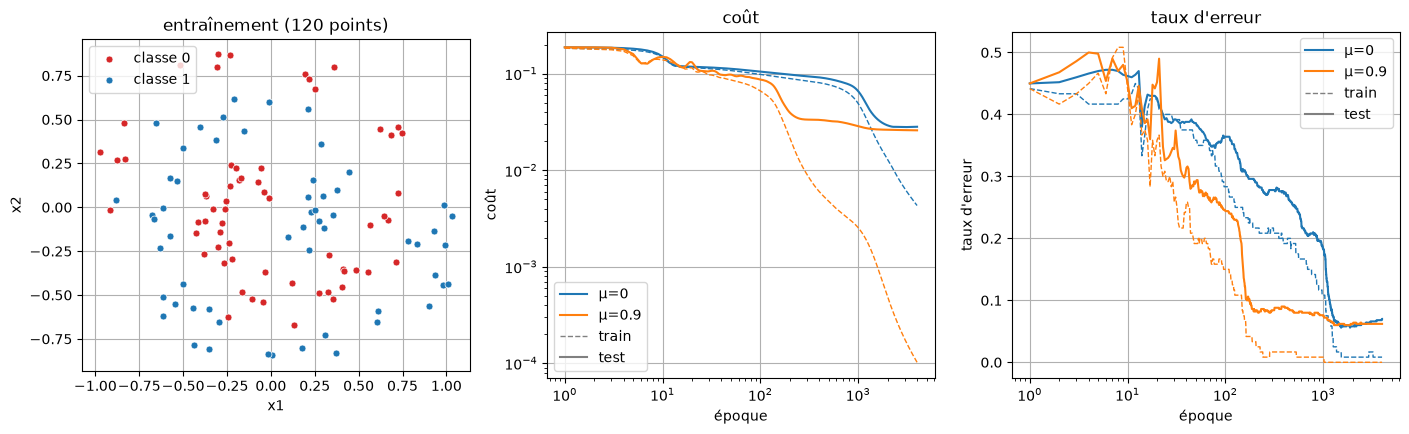

          coût train <= 0.05  err. test <= 0.10  coût test final  err. test finale
μ=0                      987               1157           0.0281             0.070
μ=0.9                    138                166           0.0258             0.062


In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_data(Xs_tr, ts_tr, ax=axes[0]); axes[0].set_title(f"entraînement ({len(ts_tr)} points)")
plot_curves(hists_sp, metric="loss", ax=axes[1]); axes[1].set_title("coût")
plot_curves(hists_sp, metric="err", ax=axes[2]); axes[2].set_title("taux d'erreur")
plt.show()

def first_below(values: list[float], level: float) -> int | None:
    """Nombre d'étapes après lequel `values` passe sous `level` (None si jamais)."""
    v = np.array(values)
    return int(np.argmax(v <= level)) + 1 if (v <= level).any() else None

print(f"{'':8s} {'coût train <= 0.05':>19s} {'err. test <= 0.10':>18s} {'coût test final':>16s} {'err. test finale':>17s}")
for name, h in hists_sp.items():
    print(f"{name:8s} {str(first_below(h['train_loss'], 0.05)):>19s} {str(first_below(h['test_err'], 0.10)):>18s} {h['test_loss'][-1]:16.4f} {h['test_err'][-1]:17.3f}")

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 14</legend>

À l'aide des courbes et du tableau :
1. Combien d'étapes chaque entraînement passe-t-il sur le plateau (jusqu'à ce que le coût d'entraînement passe sous 0.05) ? Combien de fois plus vite l'élan en sort-il ?
2. Pourquoi l'élan aide-t-il à traverser un plateau ?
3. Les deux modèles finissent-ils au même niveau ? Que vaut le surapprentissage ici ?

</fieldset>

*Votre réponse :*

# TOCLEAR
1. Sans élan, le coût d'entraînement ne baisse que très lentement pendant des centaines d'étapes (0.098 après 100 étapes, 0.077 après 500 : c'est le plateau) et ne passe sous 0.05 qu'après **987 étapes** ; avec $\mu = 0.9$, il y passe après **138 étapes**, soit environ **7 fois plus vite**. Le taux d'erreur de test passe sous 0.10 après 1157 étapes sans élan contre 166 avec élan (même facteur, environ 7).
2. Sur le plateau, le gradient est faible mais **garde le même signe** d'une étape à l'autre : sans élan chaque petit pas est oublié aussitôt, avec élan la vitesse $v \leftarrow \mu v + \eta\,\partial E/\partial W$ **accumule** ces petits pas (à l'équilibre, le pas est de l'ordre de $\eta\,\partial E/\partial W / (1 - \mu)$, soit jusqu'à 10 fois plus grand pour $\mu = 0.9$). La bille prend de la vitesse sur la pente douce et traverse la zone plate.
3. Oui : à 4000 étapes, les coûts de test sont proches (0.0281 sans élan, 0.0258 avec) et les taux d'erreur de test aussi (0.070 et 0.062). Le surapprentissage reste faible : sans élan, le coût de test atteint son minimum (0.0279) à l'indice 2906 et ne remonte presque pas ensuite, même si le taux d'erreur de test passe de 0.058 à 2000 étapes à 0.070 à la fin ; avec élan, le coût de test baisse encore à la fin. En revanche, avec élan le coût d'entraînement est devenu très faible (de l'ordre de $10^{-4}$, contre 0.004 sans élan), ce qui indique un écart entraînement/test qui se creuse. Comme au §3, l'élan change la **vitesse**, pas la destination.

### Les frontières de décision

La cellule suivante (à exécuter) réentraîne les deux modèles et trace leur frontière de décision (probabilité 0.5, points de test) après 200 étapes, puis après `EPOCHS` étapes.

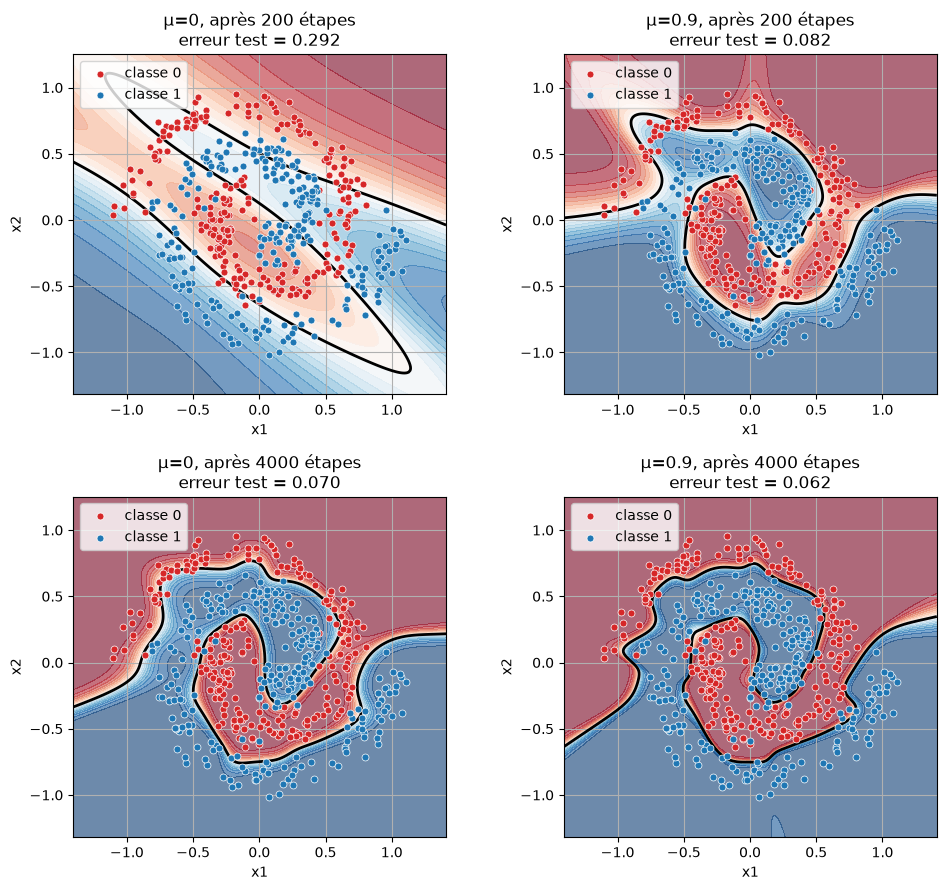

In [35]:
MOMENTUMS_SP = {"μ=0": 0.0, "μ=0.9": 0.9}
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for i, n in enumerate([200, EPOCHS]):
    for j, (name, mu) in enumerate(MOMENTUMS_SP.items()):
        m = MLPMomentum(SIZES, momentum=mu)
        m.fit(Xs_tr, ts_tr, epochs=n)
        plot_decision(m, Xs_te, ts_te, ax=axes[i, j])
        axes[i, j].set_title(f"{name}, après {n} étapes\nerreur test = {m.error_rate(Xs_te, ts_te):.3f}")
plt.tight_layout()
plt.show()

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice 15</legend>

Comparez les frontières après 200 étapes, puis après `EPOCHS` étapes.

</fieldset>

*Votre réponse :*

# TOCLEAR
Après 200 étapes, le modèle sans élan ($\mu = 0$, erreur de test 0.292) n'a encore trouvé qu'une frontière ovale grossière qui ne sépare pas les deux spirales : il est encore sur le plateau. Avec $\mu = 0.9$ (erreur 0.082), la frontière suit déjà l'enroulement des deux spirales. Après 4000 étapes, les deux frontières suivent les spirales (erreurs de test 0.070 et 0.062) : l'élan n'a pas donné un meilleur modèle, il est simplement arrivé beaucoup plus tôt ; on voit aussi que la frontière de $\mu = 0.9$ est plus anguleuse, avec un petit îlot isolé (elle épouse davantage les points d'entraînement).

## Bonus

Les explorations utilisent les lunes du §2 et du §3 (`X_tr`, `t_tr`, `X_te`, `t_te`, `SIZES`, `LR`, `MLPMomentum`, `plot_curves`).

### Régler les hyper-paramètres sans tricher

Au §3, on a comparé plusieurs $\mu$ en regardant les courbes de **test**. Si l'on se sert de ces courbes pour **choisir** $\mu$ et l'époque où s'arrêter, le jeu de test a servi à choisir : on s'est adapté à lui, et son score devient optimiste. Ce n'est plus un juge honnête : il est devenu une **validation**.

Pour juger le réglage final, il faut un troisième jeu, jamais regardé : les 500 points `X_new`, `t_new` mis de côté au §2. C'est le protocole **entraînement / validation / test** (chapitre 6, §4) :

- **entraînement** : calcule les gradients ;
- **validation** (ici `X_te`, `t_te`) : sert à choisir les hyper-paramètres, autant de fois qu'on veut ;
- **test** (ici `X_new`, `t_new`) : sert à juger le modèle final, **une seule fois**, à la fin.

S'arrêter à l'époque du minimum de la courbe de validation s'appelle l'**early stopping** (arrêt précoce).

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice bonus A</legend>

Complétez la cellule ci-dessous, en ne regardant **que** la validation (les courbes `hists[...]["test_loss"]` du §3, mesurées sur `X_te`) :
1. `name_best` : la clé de `hists` dont le minimum du coût sur `X_te` est le plus bas ;
2. `n_steps` : le nombre d'étapes à effectuer pour s'arrêter à ce minimum ;
3. `final_model` : un **nouveau** `MLPMomentum(SIZES, momentum=...)` avec l'élan choisi (`MOMENTUMS[name_best]`), entraîné `n_steps` étapes sur `X_tr`, `t_tr`.

</fieldset>

In [36]:
# BEGIN
## Rappel : hists[name]["test_loss"] est maintenant la courbe de validation du réglage name ; MOMENTUMS[name] donne son μ.
## Indice : n_steps se déduit de np.argmin, comme à l'exercice 11 ; final_model est entraîné sur X_tr, t_tr sans jeu d'évaluation.
# name_best = ...
# n_steps = ...
# final_model = ...
name_best = min(hists, key=lambda k: min(hists[k]["test_loss"]))
n_steps = int(np.argmin(hists[name_best]["test_loss"])) + 1
final_model = MLPMomentum(SIZES, momentum=MOMENTUMS[name_best])
final_model.fit(X_tr, t_tr, epochs=n_steps)
# END

{'train_loss': [0.22895573236666758,
  0.22088174682698433,
  0.20751465924532927,
  0.18008780662518895,
  0.12742544648544063,
  0.0821548464228015,
  0.07016654803251744,
  0.06483219293422081,
  0.061008570045247644,
  0.0581696026639479,
  0.05601534014240748,
  0.05434062785767303,
  0.053009498386639424,
  0.05193019868094584,
  0.051038646334421726,
  0.050288831823750324,
  0.04964720447580627,
  0.049089117382691366,
  0.04859638116258487,
  0.048155500021966,
  0.04775638398971978,
  0.04739141336829585,
  0.047054765158181085,
  0.046741931353116536,
  0.04644937524937895,
  0.04617428568027257,
  0.045914400201669724,
  0.045667876731674384,
  0.04543319933397245,
  0.04520910821484493,
  0.04499454704747215,
  0.044788622830471296,
  0.044590574921888455,
  0.044399750873589154,
  0.04421558736877561,
  0.04403759503569727,
  0.04386534623995483,
  0.04369846519077484,
  0.04353661986327668,
  0.04337951535932458,
  0.04322688841780996,
  0.0430785028505502,
  0.042934145

In [37]:
def check_early_stopping():
    assert name_best in hists, "name_best doit être une clé de hists"
    assert all(min(hists[name_best]["test_loss"]) <= min(h["test_loss"]) for h in hists.values()), "name_best n'a pas le minimum de validation le plus bas"
    assert n_steps == int(np.argmin(hists[name_best]["test_loss"])) + 1, "n_steps doit mener au minimum de validation"
    assert final_model.momentum == MOMENTUMS[name_best], "final_model n'a pas l'élan choisi"
    assert final_model.loss(X_te, t_te) == min(hists[name_best]["test_loss"]), "le coût de validation du modèle réentraîné doit valoir exactement le minimum de validation"
    print("early stopping check — OK")

check_early_stopping()

early stopping check — OK


In [38]:
print(f"réglage choisi sur la validation : {name_best}, arrêt après {n_steps} étapes")
print(f"coût de validation du modèle réentraîné : {final_model.loss(X_te, t_te):.4f}")

réglage choisi sur la validation : μ=0, arrêt après 680 étapes
coût de validation du modèle réentraîné : 0.0389


Le réglage est figé : on peut maintenant consulter le vrai test, **une seule fois**. La cellule suivante affiche la matrice de confusion et les trois métriques de `final_model` sur `X_new`, `t_new` (seuil 0.5).

In [39]:
y_new = classify(final_model.predict(X_new))
tp, fp, tn, fn = confusion(t_new, y_new)
print(f"test : {len(t_new)} points")
print(f"            prédit +   prédit -")
print(f"réel +      {tp:8d}   {fn:8d}")
print(f"réel -      {fp:8d}   {tn:8d}")
print(f"accuracy = {accuracy(t_new, y_new):.3f}  précision = {precision(t_new, y_new):.3f}  rappel = {recall(t_new, y_new):.3f}")
print(f"(taux d'erreur de validation au même moment : {final_model.error_rate(X_te, t_te):.3f})")

test : 500 points
            prédit +   prédit -
réel +           228         27
réel -            22        223
accuracy = 0.902  précision = 0.912  rappel = 0.894
(taux d'erreur de validation au même moment : 0.094)


<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice bonus B</legend>

Lisez le résultat.
1. Quel réglage la validation a-t-elle retenu, et pourquoi ne pas avoir choisi $\mu = 0.9$ qui atteint son minimum bien plus tôt ?
2. Le taux d'erreur de test est-il cohérent avec celui de validation ? Pourquoi ne doit-on surtout pas consulter le test pour choisir $\mu$ ou l'époque d'arrêt ?

</fieldset>

*Votre réponse :*

# TOCLEAR
1. La validation retient $\mu = 0$ avec un arrêt après 680 étapes : c'est le réglage dont le minimum de coût de validation est le plus bas (0.0389, contre 0.0415 pour $\mu = 0.9$ et 0.0497 pour $\mu = 0.99$). Mais l'écart avec $\mu = 0.9$ est faible (0.003) pour un coût de calcul environ 4 fois moindre (173 étapes au lieu de 680) : l'élan ne rend pas le modèle meilleur, il le fait arriver plus vite au même endroit ; c'est un choix de budget de calcul, et le critère « minimum de validation » est ici celui qui a été fixé.
2. Sur le test, l'accuracy vaut 0.902, la précision 0.912 et le rappel 0.894 (228 vrais positifs, 223 vrais négatifs, 22 faux positifs, 27 faux négatifs), soit un taux d'erreur de test de 0.098, très proche de 0.094 en validation : la validation estimait correctement la performance sur des données nouvelles. Le test n'est un juge honnête que s'il n'a pas servi à choisir : si l'on s'en servait pour comparer les $\mu$ ou les époques, le réglage s'ajusterait à ses particularités et son score deviendrait optimiste, sans plus rien dire de la performance sur de vraies données nouvelles.

### Un pas d'apprentissage plus grand

Dans tout le TD, le pas vaut `LR`. On regarde ici ce qui se passe quand on le multiplie par 16 ou par 64, sans élan et avec $\mu = 0.9$, sur les lunes et sur 500 époques.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice bonus C</legend>

Pour chaque facteur `k` de `LR_FACTORS` et chaque élan de `MUS_LR`, entraînez un `MLPMomentum(SIZES, momentum=mu)` avec le pas `lr=k * LR` et `epochs=LR_EPOCHS`, sur `X_tr`, `t_tr` en mesurant sur `X_te`, `t_te`, et rangez l'historique dans `hists_lr[k][name]`. Après la vérification, la cellule suivante trace, pour chaque pas, les courbes de coût et de taux d'erreur, puis affiche les valeurs à la dernière époque.

1. Comment évoluent le coût et le taux d'erreur de test à la dernière époque quand le pas augmente ?
2. À quoi ressemblent les courbes avec un grand pas ?
3. Avec un grand pas, l'élan aide-t-il ou aggrave-t-il les choses ?

</fieldset>

In [40]:
LR_FACTORS = (1, 16, 64)
MUS_LR = {"μ=0": 0.0, "μ=0.9": 0.9}
LR_EPOCHS = 500
hists_lr = {}
# BEGIN
## Rappel : X_tr, t_tr : entraînement ; X_te, t_te : test.
# for k in LR_FACTORS:
#     hists_lr[k] = {}
#     for name, mu in MUS_LR.items():
#         hists_lr[k][name] = ...
for k in LR_FACTORS:
    hists_lr[k] = {}
    for name, mu in MUS_LR.items():
        hists_lr[k][name] = MLPMomentum(SIZES, momentum=mu).fit(X_tr, t_tr, epochs=LR_EPOCHS, lr=k * LR, X_test=X_te, t_test=t_te)
# END

In [41]:
def check_hists_lr():
    assert list(hists_lr) == list(LR_FACTORS), f"clés attendues : {list(LR_FACTORS)} (obtenu : {list(hists_lr)})"
    for k, hh in hists_lr.items():
        assert list(hh) == list(MUS_LR), f"hists_lr[{k}] : clés attendues {list(MUS_LR)}"
        for name, h in hh.items():
            assert len(h["test_loss"]) == LR_EPOCHS, f"hists_lr[{k}][{name!r}] de mauvaise longueur"
    court = MLPMomentum(SIZES, momentum=0.9).fit(X_tr, t_tr, epochs=5, lr=16 * LR, X_test=X_te, t_test=t_te)
    assert court["test_loss"] == hists_lr[16]["μ=0.9"]["test_loss"][:5], "k=16, μ=0.9 : conditions incorrectes (pas, données ?)"
    print("hists_lr check — OK")

check_hists_lr()

hists_lr check — OK


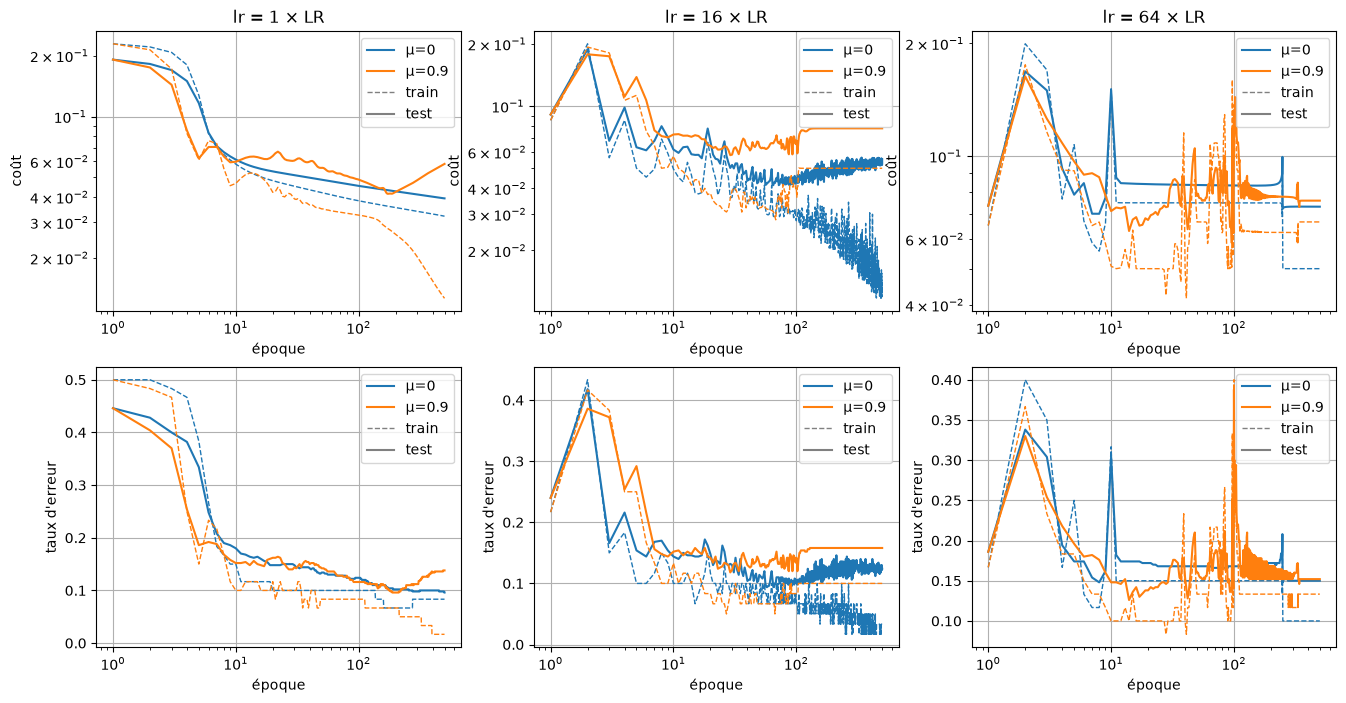

               coût test err. test coût train
lr × 1, μ=0        0.039     0.096      0.032
lr × 1, μ=0.9      0.058     0.138      0.013
lr × 16, μ=0       0.055     0.124      0.012
lr × 16, μ=0.9     0.078     0.158      0.050
lr × 64, μ=0       0.073     0.150      0.050
lr × 64, μ=0.9     0.076     0.152      0.067


In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, k in enumerate(LR_FACTORS):
    plot_curves(hists_lr[k], metric="loss", ax=axes[0, j])
    plot_curves(hists_lr[k], metric="err", ax=axes[1, j])
    axes[0, j].set_title(f"lr = {k} × LR")
plt.show()

print(f"{'':14s} {'coût test':>9s} {'err. test':>9s} {'coût train':>10s}")
for k, hh in hists_lr.items():
    for name, h in hh.items():
        print(f"{f'lr × {k}, {name}':14s} {h['test_loss'][-1]:9.3f} {h['test_err'][-1]:9.3f} {h['train_loss'][-1]:10.3f}")

*Votre réponse :*

# TOCLEAR
1. Plus le pas grandit, moins le test est bon. À l'époque 500 (test : coût / taux d'erreur, $\mu = 0$ puis $\mu = 0.9$) :
   - `lr` × 1 : 0.039 / 0.096 puis 0.058 / 0.138 ; le coût d'entraînement vaut 0.032 puis 0.013 ;
   - `lr` × 16 : 0.055 / 0.124 puis 0.078 / 0.158 ;
   - `lr` × 64 : 0.073 / 0.150 puis 0.076 / 0.152.

   À ×16 avec $\mu = 0$, le coût d'entraînement descend plus bas qu'avec le pas de départ (0.012 contre 0.032) sans gain sur le test : l'écart entre les deux se creuse.
2. Avec ×16 et $\mu = 0$, la courbe est **crénelée** (sauts d'une époque à l'autre). Avec ×64, les courbes sont chaotiques : pics brutaux dans les premières dizaines d'époques, paliers plats (sorties saturées, coût d'entraînement à 0.05 ou 0.067). Le coût ne part pas à l'infini, car tanh et sigmoïde sont bornées, mais la descente devient instable.
3. Elle les aggrave : l'élan accumule les pas, ce qui revient à agrandir encore le pas. Avec ×16 et $\mu = 0.9$, le coût d'entraînement se bloque à 0.05 ; avec ×64 et $\mu = 0.9$, de fortes oscillations apparaissent vers l'époque 100.

### D'autres valeurs de $\mu$

Au §3, on n'a essayé que trois élans. On complète ici l'échelle avec des valeurs intermédiaires. Avec un pas aussi petit, la descente de gradient simple fait baisser le coût d'entraînement à chaque époque : une **hausse** de ce coût d'une époque à l'autre signale donc une oscillation.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice bonus D</legend>

Sur les lunes, entraînez un `MLPMomentum(SIZES, momentum=mu)` pour chaque élan de `MUS_BONUS` ($\mu \in \{0.5, 0.8, 0.95\}$), dans les mêmes conditions qu'à l'exercice 10 (`epochs=EPOCHS`, jeux `X_tr`/`X_te`), et rangez chaque historique dans `hists_bonus` sous la clé correspondante. Après la vérification, la cellule suivante affiche les courbes de coût des six élans (ceux de `hists` compris) puis, pour chacun, l'indice et la valeur du minimum du coût de test et le nombre de hausses du coût d'entraînement sur les 200 premières époques.

1. Comment évoluent l'époque du minimum du coût de test et la valeur de ce minimum quand $\mu$ augmente ?
2. À partir de quelle valeur de $\mu$ apparaissent des oscillations ?

</fieldset>

In [43]:
MUS_BONUS = {"μ=0.5": 0.5, "μ=0.8": 0.8, "μ=0.95": 0.95}
hists_bonus = {}
# BEGIN
## Rappel : X_tr, t_tr : entraînement ; X_te, t_te : test ; comme à l'exercice 10.
# for name, mu in MUS_BONUS.items():
#     hists_bonus[name] = ...
for name, mu in MUS_BONUS.items():
    hists_bonus[name] = MLPMomentum(SIZES, momentum=mu).fit(X_tr, t_tr, epochs=EPOCHS, X_test=X_te, t_test=t_te)
# END

In [44]:
def check_hists_bonus():
    assert list(hists_bonus) == list(MUS_BONUS), f"clés attendues : {list(MUS_BONUS)} (obtenu : {list(hists_bonus)})"
    for name, h in hists_bonus.items():
        assert len(h["test_loss"]) == EPOCHS and len(h["train_loss"]) == EPOCHS, f"historique {name} de mauvaise longueur"
    court = MLPMomentum(SIZES, momentum=0.5).fit(X_tr, t_tr, epochs=5, X_test=X_te, t_test=t_te)
    assert court["test_loss"] == hists_bonus["μ=0.5"]["test_loss"][:5], "μ=0.5 : conditions différentes de l'exercice 10 (données ?)"
    print("hists_bonus check — OK")

check_hists_bonus()

hists_bonus check — OK


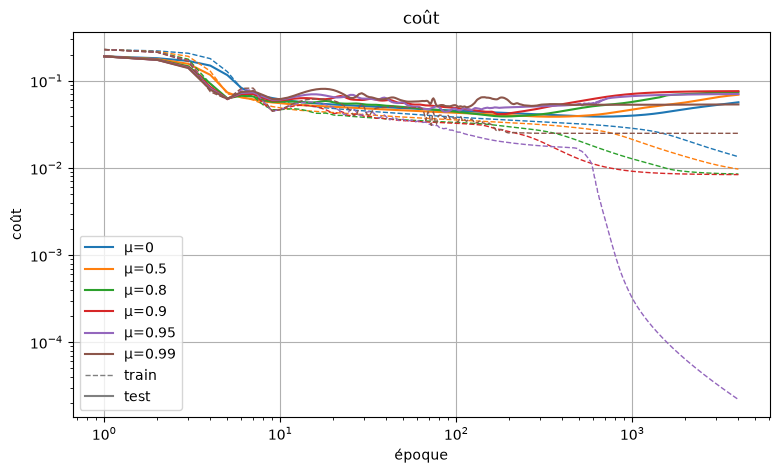

         indice du min min test  hausses train (200 premières époques)
μ=0                679   0.0389                                      0
μ=0.5              355   0.0388                                      0
μ=0.8              187   0.0390                                      5
μ=0.9              172   0.0415                                     15
μ=0.95              85   0.0443                                     34
μ=0.99             113   0.0497                                     76


In [45]:
tous = dict(sorted({**hists, **hists_bonus}.items(), key=lambda kv: float(kv[0][2:])))
fig, ax = plt.subplots(figsize=(9, 5))
plot_curves(tous, metric="loss", ax=ax)
ax.set_title("coût")
plt.show()

print(f"{'':8s} {'indice du min':>13s} {'min test':>8s} {'hausses train (200 premières époques)':>38s}")
for name, h in tous.items():
    b = int(np.argmin(h["test_loss"]))
    hausses = int(np.sum(np.diff(h["train_loss"][:200]) > 0))
    print(f"{name:8s} {b:13d} {h['test_loss'][b]:8.4f} {hausses:38d}")

*Votre réponse :*

# TOCLEAR
1. Plus $\mu$ est grand, plus le minimum du coût de test arrive tôt : indice 679 sans élan, 355 pour $\mu = 0.5$, 187 pour 0.8, 172 pour 0.9 et 85 pour 0.95 ($\mu = 0.99$, bloqué sur un plateau, fait exception avec 113). La valeur du minimum reste la même jusqu'à $\mu = 0.8$ (0.0389, 0.0388, 0.0390), puis se dégrade : 0.0415 pour 0.9, 0.0443 pour 0.95, 0.0497 pour 0.99.
2. Sans élan et avec $\mu = 0.5$, le coût d'entraînement ne remonte jamais sur les 200 premières époques. Les premières hausses apparaissent avec $\mu = 0.8$ (5 hausses), puis se multiplient : 15 pour 0.9, 34 pour 0.95, 76 pour 0.99. Les oscillations apparaissent donc vers $\mu = 0.8$ et s'amplifient quand $\mu$ s'approche de 1 ; c'est aussi à partir de là que le minimum du coût de test se dégrade.

### Le seuil de décision sur les lunes

Au §1, sur des classes déséquilibrées, baisser le seuil faisait nettement monter le rappel. On regarde ici ce qu'il en est sur les lunes, où les deux classes sont équilibrées.

<fieldset style="border: 3px solid #1976d2; border-radius: 8px; padding: 0 14px; margin: 12px 0">
<legend style="color: #1976d2; font-weight: bold; font-size: 1.5em; padding: 0 6px">✏️ Exercice bonus E</legend>

Avec `sweep_threshold` (exercice 5), calculez la précision et le rappel de `model_plain` (§2) sur le jeu de test `X_te`, `t_te`, pour chaque seuil de `thresholds_moons`, et rangez-les dans `precs_moons` et `recs_moons`. Après la vérification, la cellule suivante trace les deux courbes en fonction du seuil et affiche les valeurs aux seuils 0.1 et 0.5.

Quel seuil choisiriez-vous si manquer un positif est très coûteux ? Que gagne-t-on en rappel et que perd-on en précision par rapport au seuil 0.5 ? Comparez avec le même changement de seuil au §1 (exercice 6).

</fieldset>

In [46]:
thresholds_moons = np.linspace(0.1, 0.9, 17)
# BEGIN
## Rappel : sweep_threshold(model, X, t, thresholds) renvoie (precs, recs).
# precs_moons, recs_moons = ...
precs_moons, recs_moons = sweep_threshold(model_plain, X_te, t_te, thresholds_moons)
# END

In [47]:
def check_sweep_moons():
    assert precs_moons.shape == recs_moons.shape == thresholds_moons.shape, "precs_moons et recs_moons doivent avoir une valeur par seuil"
    Y = model_plain.predict(X_te)
    assert np.array_equal(precs_moons, np.array([precision(t_te, classify(Y, s)) for s in thresholds_moons])), "précisions incorrectes (modèle, jeu de test ?)"
    assert np.array_equal(recs_moons, np.array([recall(t_te, classify(Y, s)) for s in thresholds_moons])), "rappels incorrects (modèle, jeu de test ?)"
    print("seuil sur les lunes check — OK")

check_sweep_moons()

seuil sur les lunes check — OK


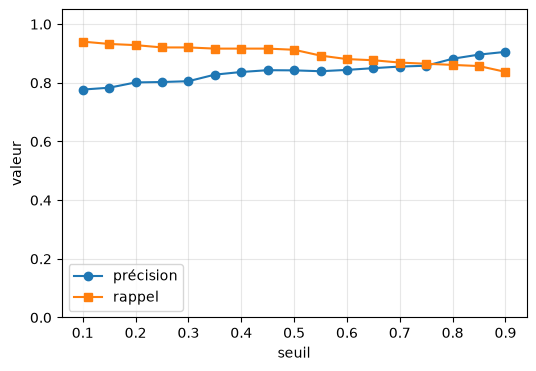

seuil 0.1 : précision 0.777, rappel 0.940
seuil 0.5 : précision 0.842, rappel 0.913


In [48]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thresholds_moons, precs_moons, "o-", label="précision")
ax.plot(thresholds_moons, recs_moons, "s-", label="rappel")
ax.set_xlabel("seuil"); ax.set_ylabel("valeur"); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.show()

for s in (0.1, 0.5):
    k = int(np.argmin(np.abs(thresholds_moons - s)))
    print(f"seuil {thresholds_moons[k]:.1f} : précision {precs_moons[k]:.3f}, rappel {recs_moons[k]:.3f}")

*Votre réponse :*

# TOCLEAR
On baisse le seuil, par exemple à 0.1 : le rappel passe de 0.913 à 0.940, la précision de 0.842 à 0.777. Le changement est bien plus faible qu'au §1, où le même passage de 0.5 à 0.1 faisait monter le rappel de 0.575 à 0.888 et descendre la précision de 0.719 à 0.438. Deux raisons : les classes sont équilibrées (252 positifs sur 500), le rappel au seuil 0.5 est donc déjà élevé ; et `model_plain`, entraîné 4000 époques, a surappris : ses sorties sont très tranchées (seules 14 % des sorties de test sont entre 0.1 et 0.9), si bien que déplacer le seuil ne fait basculer que peu de points. Le seuil 0.1 reste le choix si manquer un positif coûte cher, mais le gain est modeste.

## Conclusion

- **Matrice de confusion** : TP, FP, TN, FN, d'où accuracy, précision et rappel. Sur des classes déséquilibrées l'accuracy peut tromper (« toujours négatif » fait 0.920 au §1) ; le seuil arbitre entre précision et rappel.
- **Courbes d'apprentissage** : coût et taux d'erreur, entraînement et test sur le même graphe. Elles montrent le sous-apprentissage, le bon régime, le **surapprentissage** (le coût de test remonte) et l'instabilité (oscillations quand le pas ou $\mu$ est trop grand).
- **L'élan à conditions égales** : sur les lunes, $\mu = 0.9$ atteint le minimum du coût de test beaucoup plus tôt, donc entre aussi plus tôt dans le surapprentissage ; le minimum lui-même n'est pas plus bas. Il change la vitesse, pas la capacité.
- **Plateaux** : sur les spirales, l'élan accumule les petits gradients de même signe et sort du plateau bien plus vite ; un $\mu$ trop grand rend la descente instable (sur les lunes du §3, $\mu = 0.99$ oscille au début et bloque l'entraînement sur un plateau).
- **Bonus** : choisir les hyper-paramètres sur un jeu en fait une **validation** ; pour juger le modèle final, il faut un troisième jeu, le test, consulté une seule fois.